In [24]:
import math
import torch
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt

t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

t_un = 0.1 * t_u

print('t_c:', t_c)
print('t_un:', t_un)

t_c: tensor([ 0.5000, 14.0000, 15.0000, 28.0000, 11.0000,  8.0000,  3.0000, -4.0000,
         6.0000, 13.0000, 21.0000])
t_un: tensor([3.5700, 5.5900, 5.8200, 8.1900, 5.6300, 4.8900, 3.3900, 2.1800, 4.8400,
        6.0400, 6.8400])


In [25]:
# The nonlinear model now has three trainable parameters.
def nonlinear_model(t_u, w2, w1, b):
    return w2 * t_u ** 2 + w1 * t_u + b


# Calculate the mean squared error.
def loss_fn(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

In [26]:
# Train the nonlinear model and record the loss every 500 epochs.
def training_loop(n_epochs, learning_rate, params, t_u, t_c):
    optimizer = optim.SGD([params], lr=learning_rate)
    recorded_epochs = []
    recorded_losses = []

    for epoch in range(1, n_epochs + 1):
        t_p = nonlinear_model(t_u, *params)
        loss = loss_fn(t_p, t_c)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            loss_value = loss.item()
            recorded_epochs.append(epoch)
            recorded_losses.append(loss_value)
            print(f'Epoch {epoch}, Loss {loss_value:.6f}')

    return params, recorded_epochs, recorded_losses

In [27]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]
nonlinear_results = {}

for learning_rate in learning_rates:
    print(f'\nTraining with learning rate = {learning_rate}')

    initial_params = torch.tensor([1.0, 1.0, 0.0], requires_grad=True)

    trained_params, epochs, losses = training_loop(
        n_epochs=5000,
        learning_rate=learning_rate,
        params=initial_params,
        t_u=t_un,
        t_c=t_c
    )

    nonlinear_results[learning_rate] = {
        'params': trained_params.detach().clone(),
        'epochs': epochs,
        'losses': losses,
        'final_loss': losses[-1]
    }

    print('Final parameters:', trained_params)


Training with learning rate = 0.1
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final parameters: tensor([nan, nan, nan], requires_grad=True)

Training with learning rate = 0.01
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final parameters: tensor([nan, nan, nan], requires_grad=True)

Training with learning rate = 0.001
Epoch 500, Loss nan
Epoch 1000, Loss nan
Epoch 1500, Loss nan
Epoch 2000, Loss nan
Epoch 2500, Loss nan
Epoch 3000, Loss nan
Epoch 3500, Loss nan
Epoch 4000, Loss nan
Epoch 4500, Loss nan
Epoch 5000, Loss nan
Final parameters: tensor([nan, nan, nan], requires_grad=True)

Training with learning rate = 0.0001
Epoch 500, Loss 10.708596
Epoch 1000, Los

In [28]:
loss_table = pd.DataFrame({'Epoch': range(500, 5001, 500)})

for learning_rate in learning_rates:
    loss_table[f'LR = {learning_rate}'] = nonlinear_results[learning_rate]['losses']

loss_table

,Epoch,LR = 0.1,LR = 0.01,LR = 0.001,LR = 0.0001
0,500,NaN,NaN,NaN,10.708596
1,1000,NaN,NaN,NaN,8.642083
2,1500,NaN,NaN,NaN,7.171005
3,2000,NaN,NaN,NaN,6.123478
4,2500,NaN,NaN,NaN,5.377227
5,3000,NaN,NaN,NaN,4.845286
6,3500,NaN,NaN,NaN,4.465788
7,4000,NaN,NaN,NaN,4.194724
8,4500,NaN,NaN,NaN,4.000802
9,5000,NaN,NaN,NaN,3.861744


In [29]:
valid_rates = [
    learning_rate for learning_rate in learning_rates
    if math.isfinite(nonlinear_results[learning_rate]['final_loss'])
]

best_learning_rate = min(
    valid_rates,
    key=lambda rate: nonlinear_results[rate]['final_loss']
)

best_result = nonlinear_results[best_learning_rate]
best_params = best_result['params']
best_nonlinear_loss = best_result['final_loss']

print('Best learning rate:', best_learning_rate)
print('Best nonlinear parameters:', best_params)
print(f'Best nonlinear loss: {best_nonlinear_loss:.6f}')

Best learning rate: 0.0001
Best nonlinear parameters: tensor([ 0.5570, -0.8881, -0.8753])
Best nonlinear loss: 3.861744


In [30]:
# Define the original linear model.
def linear_model(t_u, w, b):
    return w * t_u + b


# Final parameters obtained during the lecture.
linear_params = torch.tensor([5.3671, -17.3012])

with torch.no_grad():
    linear_predictions = linear_model(t_un, *linear_params)
    linear_loss = loss_fn(linear_predictions, t_c).item()

print(f'Linear model loss:    {linear_loss:.6f}')
print(f'Nonlinear model loss: {best_nonlinear_loss:.6f}')

if best_nonlinear_loss < linear_loss:
    print('The nonlinear model performed better than the linear model.')
else:
    print('The nonlinear model performed worse than the linear model.')

Linear model loss:    2.927646
Nonlinear model loss: 3.861744
The nonlinear model performed worse than the linear model.


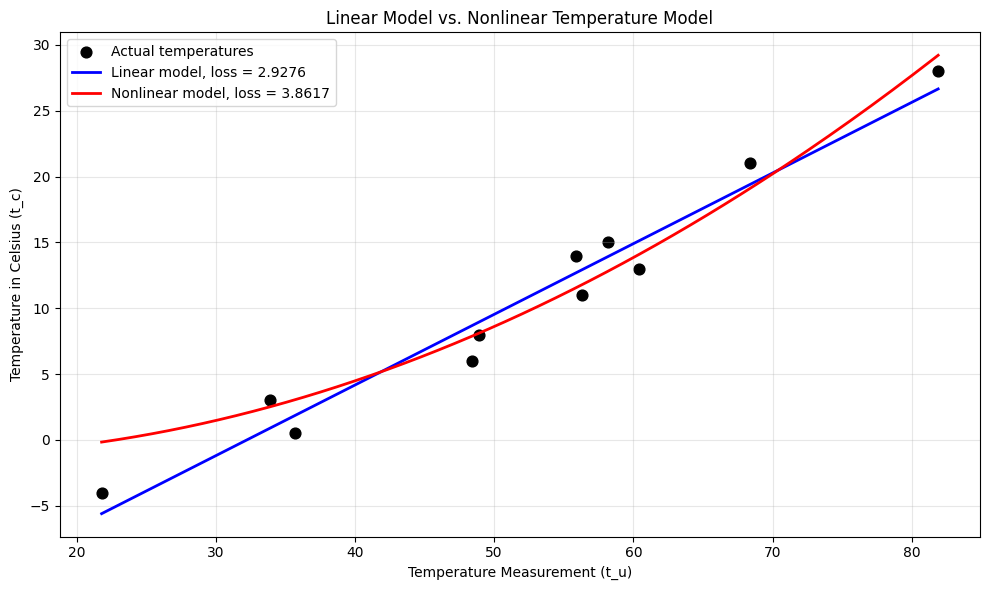

In [31]:
# Create evenly spaced inputs so the nonlinear curve appears smooth.
t_u_plot = torch.linspace(t_u.min(), t_u.max(), 200)
t_un_plot = 0.1 * t_u_plot

with torch.no_grad():
    linear_plot = linear_model(t_un_plot, *linear_params)
    nonlinear_plot = nonlinear_model(t_un_plot, *best_params)

plt.figure(figsize=(10, 6))

plt.scatter(t_u, t_c, color='black', s=60, label='Actual temperatures')
plt.plot(t_u_plot, linear_plot, color='blue', linewidth=2,
         label=f'Linear model, loss = {linear_loss:.4f}')
plt.plot(t_u_plot, nonlinear_plot, color='red', linewidth=2,
         label=f'Nonlinear model, loss = {best_nonlinear_loss:.4f}')

plt.title('Linear Model vs. Nonlinear Temperature Model')
plt.xlabel('Temperature Measurement (t_u)')
plt.ylabel('Temperature in Celsius (t_c)')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Dataset/Housing.csv'
housing = pd.read_csv(file_path)

print('Dataset shape:', housing.shape)
housing.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [33]:
housing_features = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']

X_housing = housing[housing_features].copy()
Y_housing = housing[['price']].copy()

print('Input shape:', X_housing.shape)
print('Target shape:', Y_housing.shape)
print('\nMissing values:')
print(X_housing.isnull().sum())

Input shape: (545, 5)
Target shape: (545, 1)

Missing values:
area         0
bedrooms     0
bathrooms    0
stories      0
parking      0
dtype: int64


In [34]:
X_train, X_val, Y_train, Y_val = train_test_split(
    X_housing, Y_housing, test_size=0.20, random_state=42)

print('Training input:', X_train.shape)
print('Validation input:', X_val.shape)
print('Training target:', Y_train.shape)
print('Validation target:', Y_val.shape)

Training input: (436, 5)
Validation input: (109, 5)
Training target: (436, 1)
Validation target: (109, 1)


In [35]:
housing_imputer = SimpleImputer(strategy='median')
X_train_imputed = housing_imputer.fit_transform(X_train)
X_val_imputed = housing_imputer.transform(X_val)

X_scaler = StandardScaler()
Y_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train_imputed)
X_val_scaled = X_scaler.transform(X_val_imputed)

Y_train_scaled = Y_scaler.fit_transform(Y_train).ravel()
Y_val_scaled = Y_scaler.transform(Y_val).ravel()

In [36]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

Y_train_tensor = torch.tensor(Y_train_scaled, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val_scaled, dtype=torch.float32)

In [37]:
def housing_model(X, w_area, w_bedrooms, w_bathrooms, w_stories, w_parking, b):
    return (w_area * X[:, 0] + w_bedrooms * X[:, 1] +
            w_bathrooms * X[:, 2] + w_stories * X[:, 3] +
            w_parking * X[:, 4] + b)


def housing_loss(predictions, targets):
    return ((predictions - targets) ** 2).mean()


def regression_r2(predictions, targets):
    ss_res = torch.sum((targets - predictions) ** 2)
    ss_total = torch.sum((targets - targets.mean()) ** 2)
    return 1 - ss_res / ss_total

In [38]:
def housing_training_loop(n_epochs, learning_rate, params, X_train, Y_train, X_val, Y_val):
    optimizer = optim.SGD([params], lr=learning_rate)
    history = []

    for epoch in range(1, n_epochs + 1):
        train_predictions = housing_model(X_train, *params)
        train_loss = housing_loss(train_predictions, Y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                train_predictions = housing_model(X_train, *params)
                val_predictions = housing_model(X_val, *params)

                train_loss_value = housing_loss(train_predictions, Y_train).item()
                val_loss_value = housing_loss(val_predictions, Y_val).item()
                val_r2_value = regression_r2(val_predictions, Y_val).item()

            history.append({
                'Epoch': epoch,
                'Training Loss': train_loss_value,
                'Validation Loss': val_loss_value,
                'Validation R2': val_r2_value
            })

            print(
                f'Epoch {epoch}, Training Loss {train_loss_value:.6f}, '
                f'Validation Loss {val_loss_value:.6f}, Validation R² {val_r2_value:.6f}'
            )

    return params, history

In [39]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]
housing_results = {}

for learning_rate in learning_rates:
    print(f'\nTraining with learning rate = {learning_rate}')

    initial_params = torch.zeros(6, requires_grad=True)

    trained_params, history = housing_training_loop(
        5000, learning_rate, initial_params, X_train_tensor,
        Y_train_tensor, X_val_tensor, Y_val_tensor
    )

    housing_results[learning_rate] = {
        'params': trained_params.detach().clone(),
        'history': history,
        'final_training_loss': history[-1]['Training Loss'],
        'final_validation_loss': history[-1]['Validation Loss'],
        'final_validation_r2': history[-1]['Validation R2']
    }

    print('Final parameters:', trained_params)


Training with learning rate = 0.1
Epoch 500, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 1000, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 1500, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 2000, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 2500, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 3000, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 3500, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 4000, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 4500, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Epoch 5000, Training Loss 0.437832, Validation Loss 0.743571, Validation R² 0.546406
Final parameters: tensor([3.8729e-01, 6.4337e-02, 3.2199e-01, 2.4167e-01, 1.6421e-01, 1.4576e-08],
       requires_g

In [40]:
loss_report = []

for learning_rate, result in housing_results.items():
    for row in result['history']:
        loss_report.append({
            'Learning Rate': learning_rate,
            'Epoch': row['Epoch'],
            'Training Loss': row['Training Loss'],
            'Validation Loss': row['Validation Loss'],
            'Validation R2': row['Validation R2']
        })

loss_report_df = pd.DataFrame(loss_report)
loss_report_df

,Learning Rate,Epoch,Training Loss,Validation Loss,Validation R2
0,0.1000,500,0.437832,0.743571,0.546406
1,0.1000,1000,0.437832,0.743571,0.546406
2,0.1000,1500,0.437832,0.743571,0.546406
3,0.1000,2000,0.437832,0.743571,0.546406
4,0.1000,2500,0.437832,0.743571,0.546406
5,0.1000,3000,0.437832,0.743571,0.546406
6,0.1000,3500,0.437832,0.743571,0.546406
7,0.1000,4000,0.437832,0.743571,0.546406
8,0.1000,4500,0.437832,0.743571,0.546406
9,0.1000,5000,0.437832,0.743571,0.546406


In [41]:
best_learning_rate = min(
    learning_rates,
    key=lambda rate: housing_results[rate]['final_validation_loss']
)

best_housing_result = housing_results[best_learning_rate]
best_housing_params = best_housing_result['params']

print('Best learning rate:', best_learning_rate)
print('Best standardized parameters:', best_housing_params)
print(f"Training loss:   {best_housing_result['final_training_loss']:.6f}")
print(f"Validation loss: {best_housing_result['final_validation_loss']:.6f}")
print(f"Validation R²:   {best_housing_result['final_validation_r2']:.6f}")

Best learning rate: 0.1
Best standardized parameters: tensor([3.8729e-01, 6.4337e-02, 3.2199e-01, 2.4167e-01, 1.6421e-01, 1.4576e-08])
Training loss:   0.437832
Validation loss: 0.743571
Validation R²:   0.546406


In [42]:
with torch.no_grad():
    best_val_predictions_scaled = housing_model(
        X_val_tensor, *best_housing_params
    ).numpy().reshape(-1, 1)

best_val_predictions = Y_scaler.inverse_transform(
    best_val_predictions_scaled
).ravel()

Y_val_actual = Y_val.to_numpy().ravel()

housing_mae = mean_absolute_error(Y_val_actual, best_val_predictions)
housing_rmse = np.sqrt(mean_squared_error(Y_val_actual, best_val_predictions))
housing_r2 = r2_score(Y_val_actual, best_val_predictions)

print(f'MAE:  ${housing_mae:,.2f}')
print(f'RMSE: ${housing_rmse:,.2f}')
print(f'R²:    {housing_r2:.6f}')

MAE:  $1,127,483.50
RMSE: $1,514,173.59
R²:    0.546406


In [43]:
scaled_weights = best_housing_params[:5].numpy()
scaled_bias = best_housing_params[5].item()

original_weights = (
    Y_scaler.scale_[0] * scaled_weights / X_scaler.scale_
)

original_bias = (
    Y_scaler.mean_[0] + Y_scaler.scale_[0] * scaled_bias -
    np.dot(original_weights, X_scaler.mean_)
)

parameter_table = pd.DataFrame({
    'Parameter': housing_features + ['bias'],
    'Value': list(original_weights) + [original_bias]
})

parameter_table

,Parameter,Value
0,area,3.088669e+02
1,bedrooms,1.512468e+05
2,bathrooms,1.185731e+06
3,stories,4.951007e+05
4,parking,3.376609e+05
5,bias,5.200003e+04


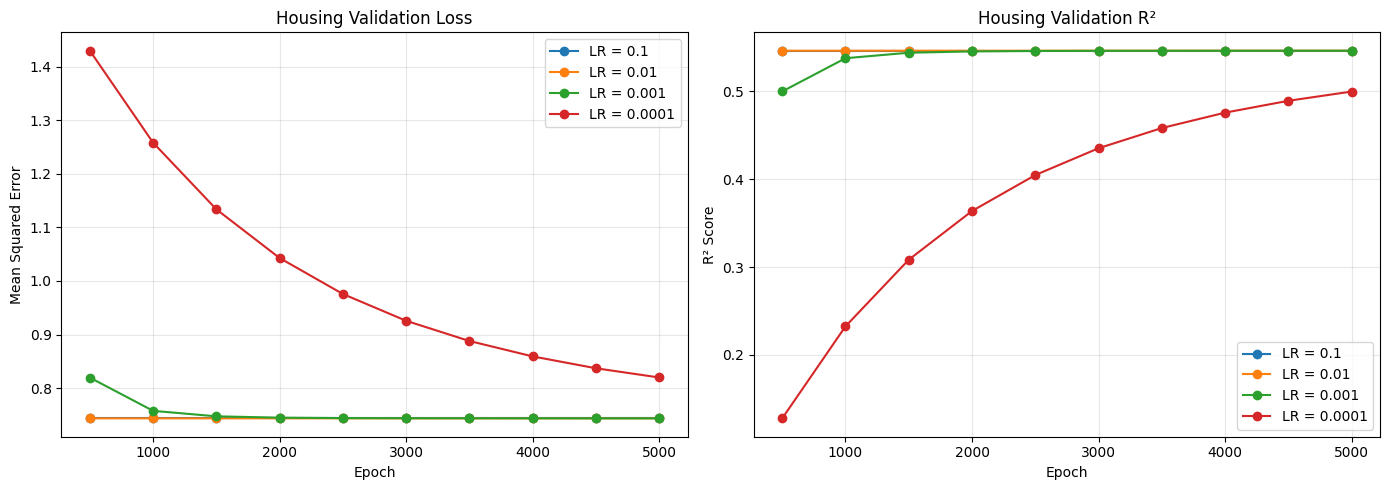

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for learning_rate in learning_rates:
    result_df = pd.DataFrame(housing_results[learning_rate]['history'])

    axes[0].plot(
        result_df['Epoch'], result_df['Validation Loss'],
        marker='o', label=f'LR = {learning_rate}'
    )

    axes[1].plot(
        result_df['Epoch'], result_df['Validation R2'],
        marker='o', label=f'LR = {learning_rate}'
    )

axes[0].set_title('Housing Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mean Squared Error')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title('Housing Validation R²')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('R² Score')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

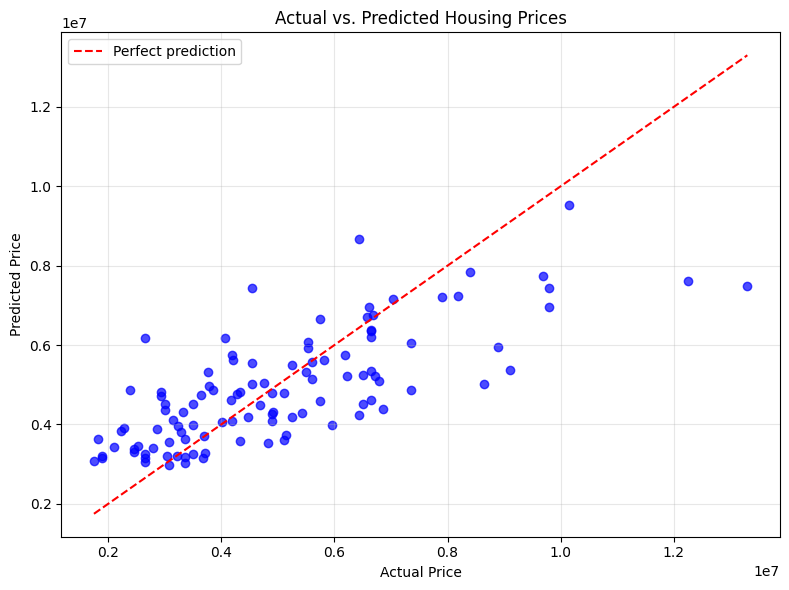

In [47]:
minimum_price = min(Y_val_actual.min(), best_val_predictions.min())
maximum_price = max(Y_val_actual.max(), best_val_predictions.max())

plt.figure(figsize=(8, 6))
plt.scatter(Y_val_actual, best_val_predictions, color='blue', alpha=0.7)
plt.plot([minimum_price, maximum_price], [minimum_price, maximum_price],
         color='red', linestyle='--', label='Perfect prediction')

plt.title('Actual vs. Predicted Housing Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [52]:
# Using all housing features except the target price
X_all = housing.drop("price", axis=1).copy()
Y_all = housing["price"].copy()

# Convert yes/no columns into 1/0
yes_no_columns = ["mainroad", "guestroom", "basement", "hotwaterheating",
                  "airconditioning", "prefarea"]

for column in yes_no_columns:
    X_all[column] = X_all[column].map({"yes": 1, "no": 0})

# Convert furnishing status into dummy variables
X_all = pd.get_dummies(X_all, columns=["furnishingstatus"],
                       drop_first=True, dtype=float)

print(X_all.columns)
print("X shape:", X_all.shape)
print("Y shape:", Y_all.shape)

Index(['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom',
       'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea',
       'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished'],
      dtype='object')
X shape: (545, 13)
Y shape: (545,)


In [53]:
X_all_train, X_all_val, Y_all_train, Y_all_val = train_test_split(
    X_all, Y_all, test_size=0.2, random_state=42
)

# Fill any missing values using only the training data
all_imputer = SimpleImputer(strategy="median")
X_all_train = all_imputer.fit_transform(X_all_train)
X_all_val = all_imputer.transform(X_all_val)

# Standardize the input features
all_X_scaler = StandardScaler()
X_all_train_scaled = all_X_scaler.fit_transform(X_all_train)
X_all_val_scaled = all_X_scaler.transform(X_all_val)

# Standardize housing price
all_Y_scaler = StandardScaler()
Y_all_train_scaled = all_Y_scaler.fit_transform(
    Y_all_train.to_numpy().reshape(-1, 1)
).ravel()

Y_all_val_scaled = all_Y_scaler.transform(
    Y_all_val.to_numpy().reshape(-1, 1)
).ravel()

print("Training shape:", X_all_train_scaled.shape)
print("Validation shape:", X_all_val_scaled.shape)

Training shape: (436, 13)
Validation shape: (109, 13)


In [54]:
X_all_train_tensor = torch.tensor(X_all_train_scaled, dtype=torch.float32)
X_all_val_tensor = torch.tensor(X_all_val_scaled, dtype=torch.float32)

Y_all_train_tensor = torch.tensor(Y_all_train_scaled, dtype=torch.float32)
Y_all_val_tensor = torch.tensor(Y_all_val_scaled, dtype=torch.float32)

# Linear model with all features and one bias
def all_feature_model(X, theta):
    return X @ theta[:-1] + theta[-1]


def train_all_feature_model(learning_rate, epochs=5000):
    parameter_count = X_all_train_tensor.shape[1] + 1
    theta = torch.zeros(parameter_count, requires_grad=True)

    optimizer = torch.optim.SGD([theta], lr=learning_rate)

    epoch_history = []
    training_losses = []
    validation_losses = []
    validation_r2 = []

    print(f"\nTraining with learning rate = {learning_rate}")

    for epoch in range(1, epochs + 1):
        prediction = all_feature_model(X_all_train_tensor, theta)
        loss = torch.mean((prediction - Y_all_train_tensor) ** 2)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            with torch.no_grad():
                training_prediction = all_feature_model(
                    X_all_train_tensor, theta
                )

                validation_prediction = all_feature_model(
                    X_all_val_tensor, theta
                )

                training_loss = torch.mean(
                    (training_prediction - Y_all_train_tensor) ** 2
                ).item()

                validation_loss = torch.mean(
                    (validation_prediction - Y_all_val_tensor) ** 2
                ).item()

                r2 = r2_score(
                    Y_all_val_tensor.numpy(),
                    validation_prediction.numpy()
                )

            epoch_history.append(epoch)
            training_losses.append(training_loss)
            validation_losses.append(validation_loss)
            validation_r2.append(r2)

            print(
                f"Epoch {epoch}, Training Loss {training_loss:.6f}, "
                f"Validation Loss {validation_loss:.6f}, "
                f"Validation R² {r2:.6f}"
            )

    print("Final parameters:", theta)

    return {
        "theta": theta.detach().clone(),
        "epochs": epoch_history,
        "training_losses": training_losses,
        "validation_losses": validation_losses,
        "validation_r2": validation_r2
    }

In [55]:
all_learning_rates = [0.1, 0.01, 0.001, 0.0001]
all_training_results = {}

for learning_rate in all_learning_rates:
    all_training_results[learning_rate] = train_all_feature_model(
        learning_rate, epochs=5000)


Training with learning rate = 0.1
Epoch 500, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 1000, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 1500, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 2000, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 2500, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 3000, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 3500, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 4000, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 4500, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Epoch 5000, Training Loss 0.314056, Validation Loss 0.568957, Validation R² 0.652924
Final parameters: tensor([ 2.9588e-01,  3.2660e-02,  2.9720e-01,  1.9889e-01,  7.3179e-02,
         5.0553e-02,  1.0

In [56]:
best_all_lr = min(
    all_learning_rates,
    key=lambda lr: all_training_results[lr]["validation_losses"][-1]
)

best_all_result = all_training_results[best_all_lr]
best_all_theta = best_all_result["theta"]

print("\nBest learning rate:", best_all_lr)
print("Best final validation loss:",
      best_all_result["validation_losses"][-1])

print("Best final validation R²:",
      best_all_result["validation_r2"][-1])

print("Best parameters:", best_all_theta)


Best learning rate: 0.001
Best final validation loss: 0.5687652230262756
Best final validation R²: 0.6530413627624512
Best parameters: tensor([ 2.9518e-01,  3.3704e-02,  2.9712e-01,  1.9768e-01,  7.3727e-02,
         5.1253e-02,  1.0554e-01,  8.5477e-02,  2.0845e-01,  1.0948e-01,
         1.5184e-01, -3.5324e-02, -1.0890e-01,  1.4898e-08])


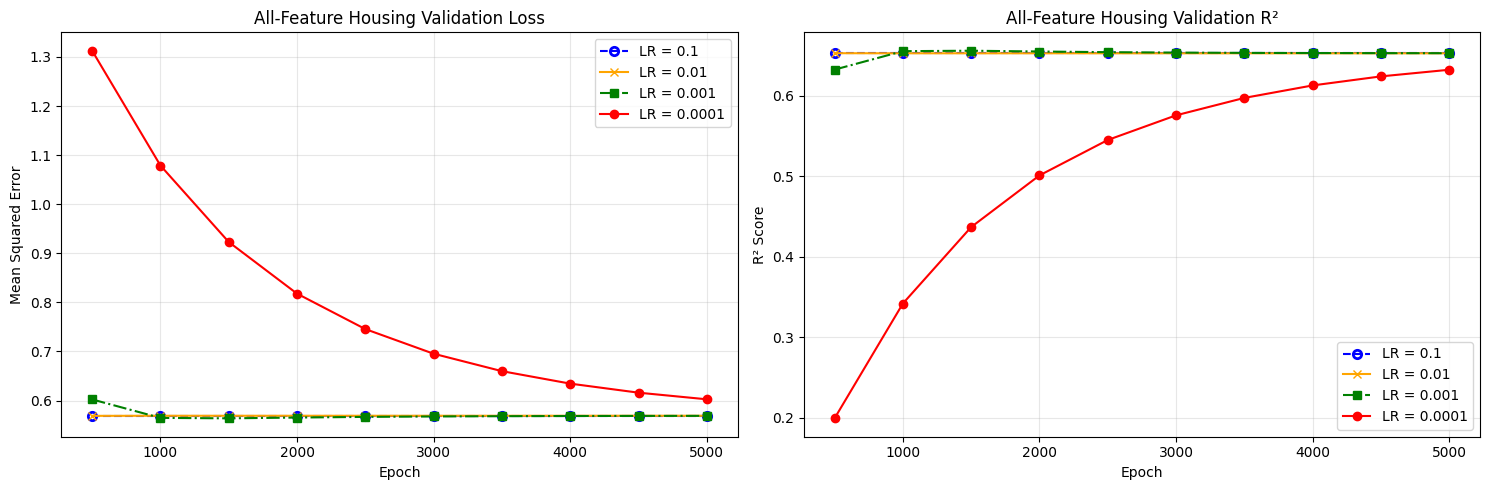

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_styles = {
    0.1: {"color": "blue", "marker": "o", "linestyle": "--",
          "markerfacecolor": "none", "markeredgewidth": 2},

    0.01: {"color": "orange", "marker": "x", "linestyle": "-"},

    0.001: {"color": "green", "marker": "s", "linestyle": "-."},

    0.0001: {"color": "red", "marker": "o", "linestyle": "-"}
}

for learning_rate in all_learning_rates:
    result = all_training_results[learning_rate]
    style = plot_styles[learning_rate]

    axes[0].plot(
        result["epochs"], result["validation_losses"],
        label=f"LR = {learning_rate}", **style
    )

    axes[1].plot(
        result["epochs"], result["validation_r2"],
        label=f"LR = {learning_rate}", **style
    )

axes[0].set_title("All-Feature Housing Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Mean Squared Error")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].set_title("All-Feature Housing Validation R²")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R² Score")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

In [58]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

with torch.no_grad():
    all_prediction_scaled = all_feature_model(
        X_all_val_tensor, best_all_theta
    ).numpy()

all_predictions = all_Y_scaler.inverse_transform(
    all_prediction_scaled.reshape(-1, 1)
).ravel()

all_actual_prices = Y_all_val.to_numpy()

all_mae = mean_absolute_error(all_actual_prices, all_predictions)
all_rmse = np.sqrt(mean_squared_error(all_actual_prices, all_predictions))
all_r2 = r2_score(all_actual_prices, all_predictions)

print(f"MAE:  ${all_mae:,.2f}")
print(f"RMSE: ${all_rmse:,.2f}")
print(f"R²:    {all_r2:.6f}")

MAE:  $969,394.88
RMSE: $1,324,283.47
R²:    0.653041


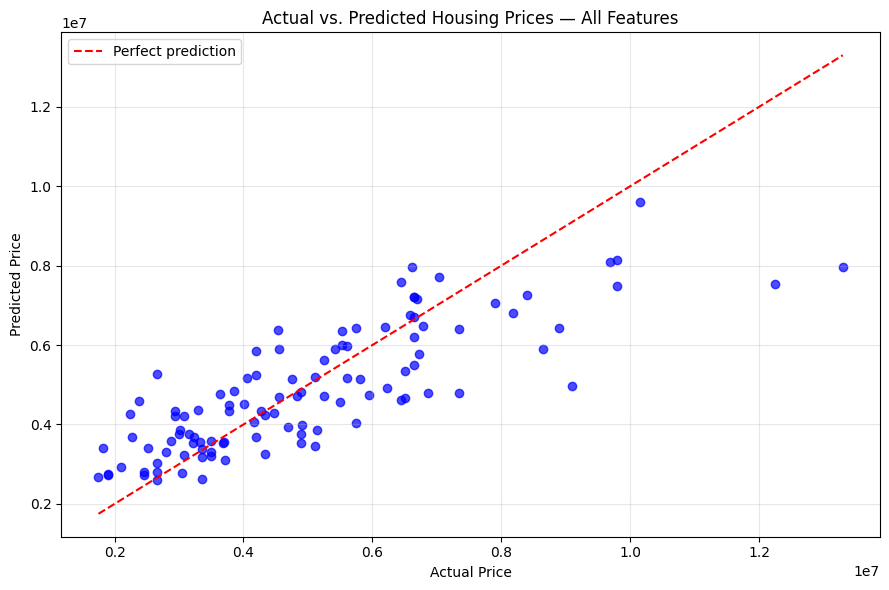

In [59]:
plt.figure(figsize=(9, 6))

plt.scatter(
    all_actual_prices, all_predictions,
    color="blue", alpha=0.7
)

minimum_price = min(all_actual_prices.min(), all_predictions.min())
maximum_price = max(all_actual_prices.max(), all_predictions.max())

plt.plot(
    [minimum_price, maximum_price],
    [minimum_price, maximum_price],
    color="red", linestyle="--",
    label="Perfect prediction"
)

plt.title("Actual vs. Predicted Housing Prices — All Features")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [60]:
scaled_weights = best_all_theta[:-1].numpy()
scaled_bias = best_all_theta[-1].item()

raw_weights = (
    all_Y_scaler.scale_[0] * scaled_weights
    / all_X_scaler.scale_
)

raw_bias = (
    all_Y_scaler.mean_[0]
    + all_Y_scaler.scale_[0] * scaled_bias
    - np.sum(raw_weights * all_X_scaler.mean_)
)

all_parameter_table = pd.DataFrame({
    "Parameter": list(X_all.columns) + ["bias"],
    "Value": list(raw_weights) + [raw_bias]
})

all_parameter_table

,Parameter,Value
0,area,2.354094e+02
1,bedrooms,7.923270e+04
2,bathrooms,1.094141e+06
3,stories,4.049975e+05
4,mainroad,3.706787e+05
5,guestroom,2.348175e+05
6,basement,3.866250e+05
7,hotwaterheating,6.857048e+05
8,airconditioning,7.933212e+05
9,parking,2.251186e+05
